# Phase 4A – The coach's three questions

1. **Q1:** Does the **lane colour** (red or blue) affect how the dogs perform?
2. **Q2:** Does it matter whether a dog **passes onto an intact or neutered male or female**?
3. **Q3:** Everything from Phase 3 **per competition** (venue and date), with the weather attached.

**How to read the answers.** A yes/no question needs two tests, not one:

- *Is there a difference?* An effect with a 95 % confidence interval (CI), and a p-value corrected for running many tests (Holm or Benjamini-Hochberg).
- *Is it big enough to matter?* An **equivalence test (TOST)** against the smallest difference that matters to the coach: **0.05 s per dog run**, 0.2 s per heat, 0.02 s per start or pass, and 2 percentage points for any rate.

Every result gets one of four verdicts:

| Verdict | Meaning |
|---|---|
| **meaningful difference** | different from zero, and possibly larger than the margin |
| **real but negligible** | measurably different, but proven smaller than the margin |
| **no effect (equivalent)** | proven to be inside the margin |
| **inconclusive** | the data can't tell; usually too few dogs |

All code is in `src/flyball/lane.py`, `partner.py` and `competition.py`. `scripts/run_phase4a.py` rebuilds every table (`reports/phase4a/`) and figure (`figures/phase4/`). Details and counts are in `ANALYSIS_LOG.md` Step 4.

In [1]:
import warnings

import pandas as pd
from IPython.display import Image, display

from flyball import competition, config, lane, metrics, partner
from flyball.plots import phase4 as plots, style

warnings.simplefilter("ignore")          # MixedLM convergence chatter
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 45)
pd.set_option("display.precision", 3)
style.apply()

t = metrics.load_processed()
heats, runs = t["heats"], t["runs"]
samples = {"field": (heats, runs[runs["dog_key"].notna()]),
           "WRFT": (heats[heats["is_wrft"]], runs[runs["is_wrft_dog"]])}

---
## Q1 – Lane colour

### 1.1 How are lanes assigned?

Before comparing lanes, check how teams end up in them. If strong teams always got the red lane, a lane difference would really be a team difference.

In [2]:
assignment = lane.lane_assignment(heats)
display(assignment["summary"])
display(assignment["wrft_teams"])

,check,count,out_of,share
0,lane switches between consecutive heats o...,4,6211,6.440e-04
1,race-teams in the red lane,1166,2332,5.000e-01
2,paired heats where the first-listed team ...,4226,4226,1.000e+00


,team_norm,races,red,red_share,p_value,p_holm
0,wildrunners dreamers,52,30,0.577,0.332,1.0
1,wildrunners hopefuls,52,25,0.481,0.890,1.0
2,wildrunners maximini,65,33,0.508,1.000,1.0
3,wildrunners nightfall,45,22,0.489,1.000,1.0
4,wildrunners wonders,12,7,0.583,0.774,1.0
5,wildrunners xxl,31,15,0.484,1.000,1.0
6,wildrunners zephyr,60,29,0.483,0.897,1.0


- **The lane is drawn once per race, not per heat.** A team keeps its lane for the whole race (4 switches in 6,211 consecutive heats), and the first team listed on the sheet is always blue. The lane follows the running order, not the team's strength.
- Red and blue are exactly balanced over the season, and no WRFT team got one lane more often than chance (all Holm p = 1.0).
- **Consequence for the models:** heats of one race share their lane, so they are not independent evidence. Standard errors are **clustered on race**.

### 1.2 Does lane colour change a dog's run time?

Two models compare a dog **with itself**:

- **mixed:** the Phase 3 dog model (dog as a random effect; position, hurdle height and ring-day accounted for) with the lane added;
- **within dog-day:** only the same dog on the same day, once in the red lane and once in the blue (errors clustered on race).

In [3]:
run_effect = pd.concat([lane.lane_run_effect(r, s) for s, (_, r) in samples.items()], ignore_index=True)
display(run_effect)

,sample,model,runs,dogs,median_run_s,pct,seconds,ci_low_s,ci_high_s,p_value,p_tost,verdict
0,field,mixed,32777,903,4.27,0.152,0.007,0.003,0.010,4.575e-05,1.316e-163,real but negligible
1,field,within dog-day,32777,903,4.27,0.151,0.006,0.003,0.010,6.224e-04,1.355e-118,real but negligible
2,WRFT,mixed,4340,50,4.28,0.079,0.003,-0.006,0.013,4.926e-01,8.562e-22,no effect (equivalent)
3,WRFT,within dog-day,4340,50,4.28,0.140,0.006,-0.006,0.018,3.322e-01,4.789e-13,no effect (equivalent)


- **Field (903 dogs, 32,777 runs):** blue is slower by **0.006 s per run** (95 % CI 0.003–0.010 s). With this many runs the difference is statistically real, but it is **8 times smaller than the 0.05 s margin** and below the timing display's 0.01 s resolution. Verdict: **real but negligible**.
- **WRFT dogs (50 dogs, 4,340 runs):** +0.003 to +0.006 s, CI −0.006 to +0.018 s. Verdict: **no effect (equivalent)**.

### 1.3 Is any venue lopsided?

A lane asymmetry would come from the venue (sun, slope, ground wear), so the lane effect is estimated separately for each of the 28 ring-days, using all dogs.

Is the lane effect the same on every ring-day? {'chi2': 77.591885263831, 'df': 27, 'p_value': 8.703131008822852e-07}


,competition,ring,date,runs,seconds,ci_low_s,ci_high_s,p_bh,verdict
0,Hanácké škvarek,<NA>,2023-04-22,410,-9.024e-03,-3.404e-02,0.016,7.584e-01,no effect (equivalent)
1,Hanácké škvarek,<NA>,2023-04-23,481,-2.579e-02,-5.523e-02,0.004,2.189e-01,inconclusive
2,Eager´s Cup,1,2023-05-06,1171,2.125e-02,4.680e-03,0.038,4.782e-02,real but negligible
3,Eager´s Cup,1,2023-05-07,1288,3.197e-03,-9.647e-03,0.016,8.716e-01,no effect (equivalent)
4,Eager´s Cup,2,2023-05-06,1254,-1.966e-02,-3.259e-02,-0.007,2.014e-02,real but negligible
5,Eager´s Cup,2,2023-05-07,1454,7.782e-03,-1.259e-02,0.028,7.584e-01,no effect (equivalent)
6,Flyvaryors turnaj,<NA>,2023-05-20,1350,1.317e-03,-1.604e-02,0.019,9.496e-01,no effect (equivalent)
7,Flyvaryors turnaj,<NA>,2023-05-21,1496,-8.937e-03,-2.419e-02,0.006,5.557e-01,no effect (equivalent)
8,MED's Trophy,<NA>,2023-06-10,1070,-6.885e-03,-2.632e-02,0.013,7.584e-01,no effect (equivalent)
9,MED's Trophy,<NA>,2023-06-11,1142,7.060e-03,-3.097e-02,0.045,8.716e-01,no effect (equivalent)


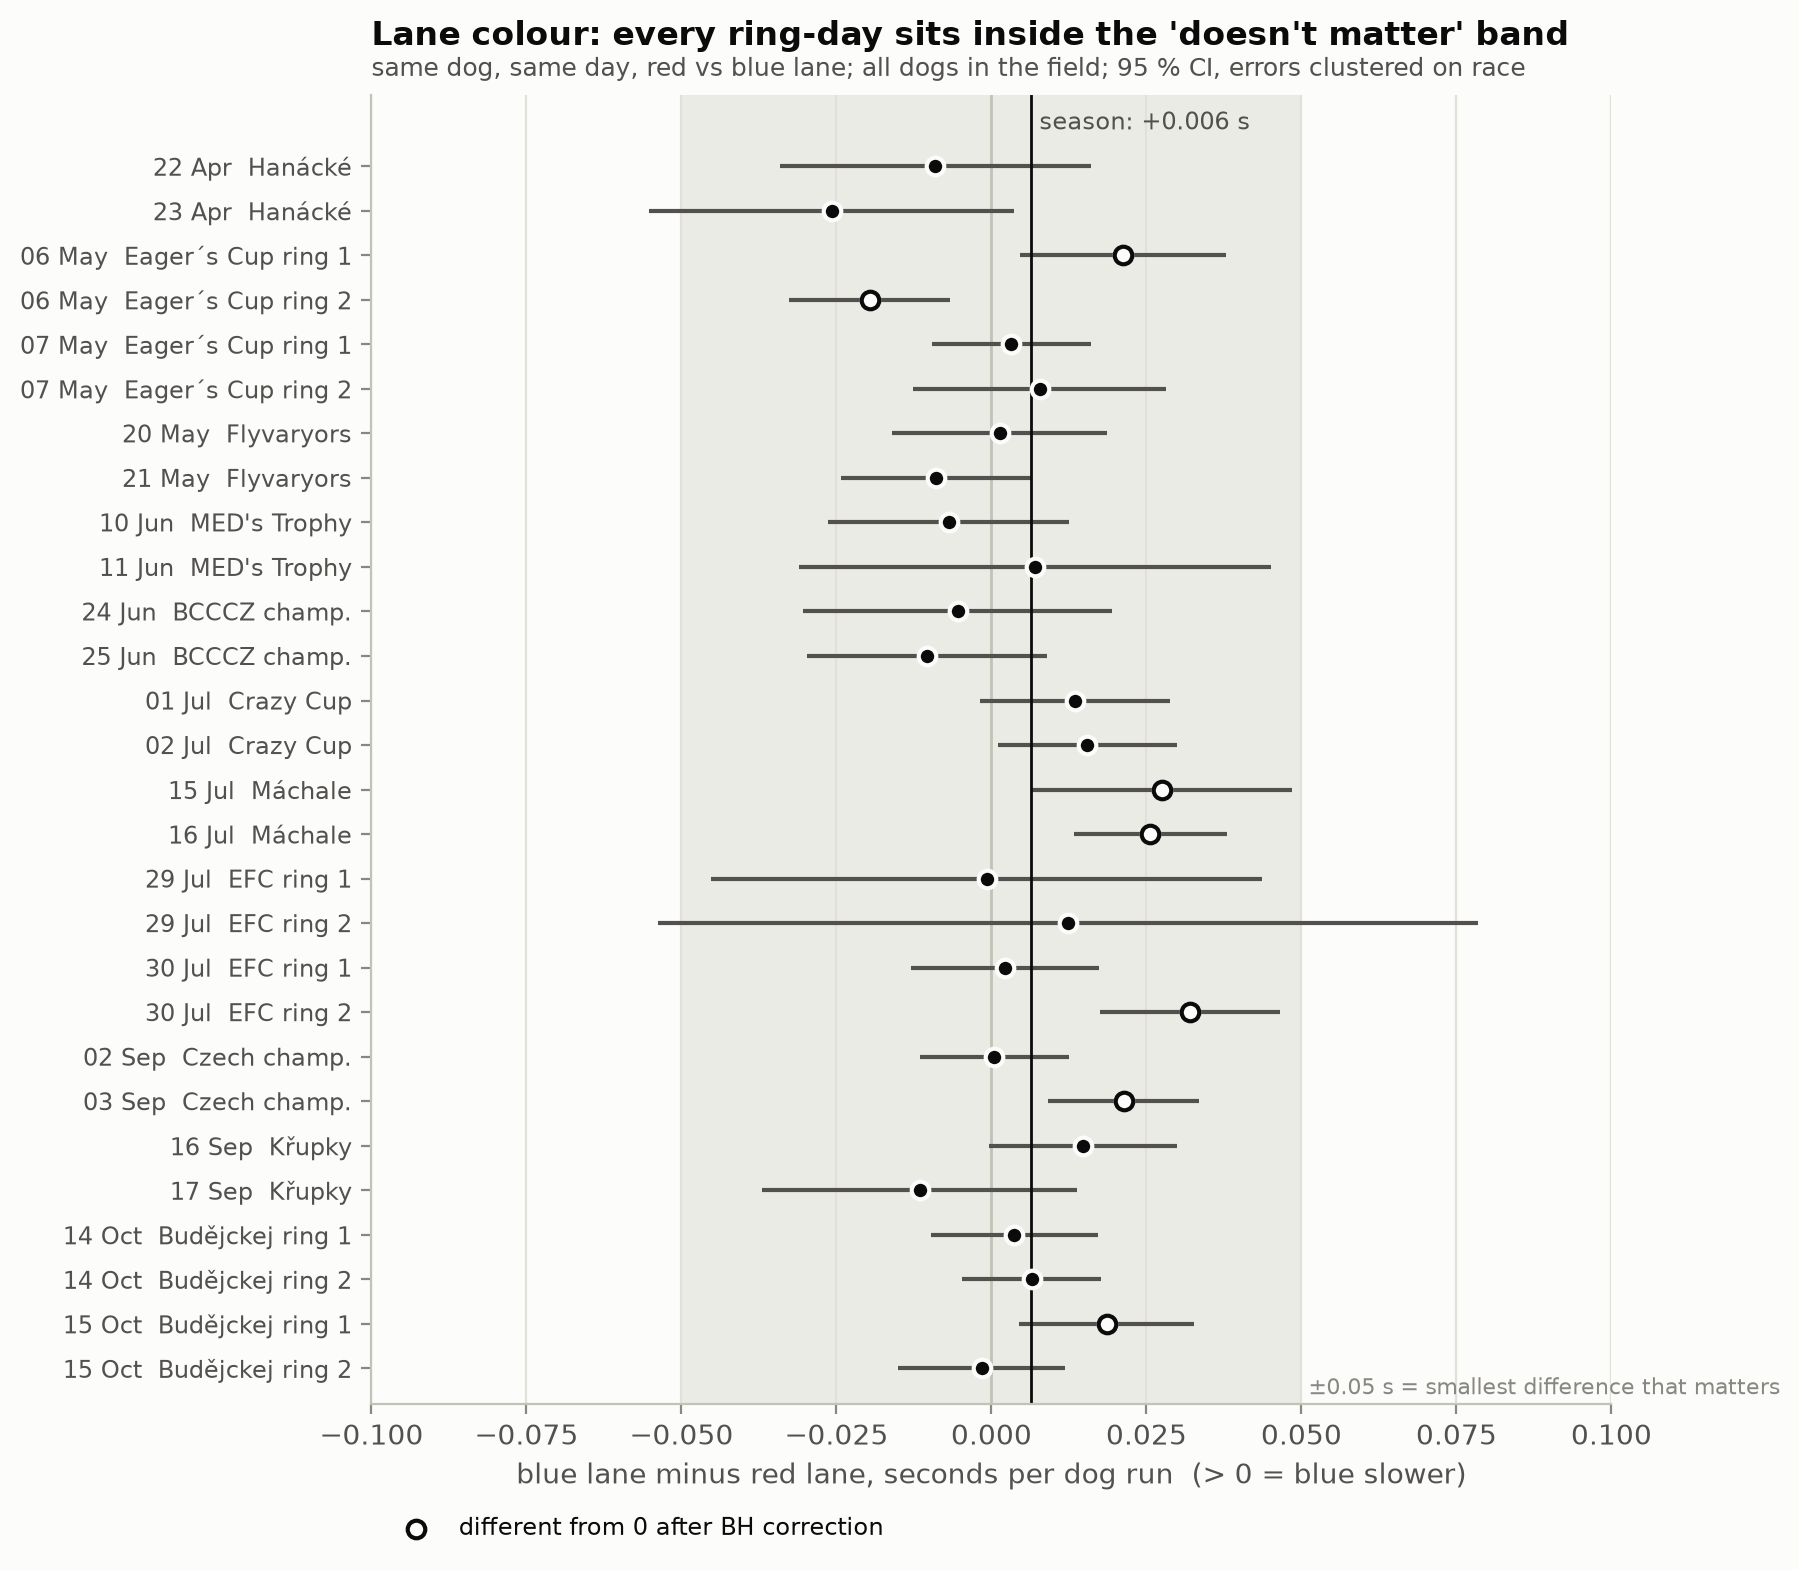

In [4]:
lane_days = lane.lane_by_ring_day(runs)
print("Is the lane effect the same on every ring-day?", lane_days.attrs["heterogeneity"])
display(lane_days[["competition", "ring", "date", "runs", "seconds", "ci_low_s", "ci_high_s", "p_bh", "verdict"]])
display(Image(style.save(plots.lane_ring_days(lane_days, run_effect), "lane_ring_days", "phase4")))

- The lane effect **does differ between ring-days** (χ² = 78, 27 df, p < 0.000001). 7 ring-days show a lane difference after the BH correction. In 6 the blue lane is slower (Máchale both days, Czech championship Sunday, EFC ring 2 Sunday, Budějckej ring 1 Sunday, Eager's Cup ring 1 Saturday). In 1 the red lane is slower (Eager's Cup ring 2 Saturday). The two rings at Eager's Cup point in opposite directions on the same day, so these look like local ring set-ups, not a general pattern.
- **But every ring-day is inside the ±0.05 s band.** The largest effect is 0.032 s per run (EFC ring 2, Sunday), about 0.13 s over a 4-dog heat. Real venue asymmetries exist, and they are too small to change a result.

### 1.4 Starts, passes, faults and wins by lane

In [5]:
outcomes = pd.concat([lane.lane_outcomes(h, r, s) for s, (h, r) in samples.items()], ignore_index=True)
display(outcomes[["sample", "outcome", "red", "blue", "blue_minus_red", "ci_low", "ci_high", "p_holm", "p_tost", "verdict"]])

,sample,outcome,red,blue,blue_minus_red,ci_low,ci_high,p_holm,p_tost,verdict
0,field,"run time (log, per run)",4.250,4.280,6.556e-03,0.003,0.010,0.008,2.413e-111,real but negligible
1,field,clean heat time,17.420,17.470,3.071e-02,-0.030,0.091,1.000,2.242e-08,no effect (equivalent)
2,field,start time,0.100,0.100,-4.803e-04,-0.005,0.004,1.000,2.304e-16,no effect (equivalent)
3,field,pass time,0.150,0.160,1.046e-02,0.002,0.019,0.143,1.271e-02,no effect (equivalent)
4,field,"pass time, held passes (> 1 s) left out",0.150,0.150,3.303e-03,-0.002,0.008,1.000,9.303e-11,no effect (equivalent)
5,field,tight-pass (ok) share,0.340,0.343,-7.255e-03,-0.020,0.006,1.000,2.843e-02,no effect (equivalent)
6,field,clean-heat rate,0.562,0.564,-5.148e-04,-0.022,0.021,1.000,3.544e-02,no effect (equivalent)
7,field,false-start rate (heat),0.115,0.110,-2.635e-03,-0.016,0.011,1.000,4.796e-03,no effect (equivalent)
8,field,early-pass rate (heat),0.222,0.230,-3.113e-03,-0.021,0.015,1.000,3.234e-02,no effect (equivalent)
9,field,run-fault rate (heat),0.057,0.061,7.363e-03,-0.003,0.017,1.000,7.266e-03,no effect (equivalent)


- **Field:** every outcome is **equivalent** across lanes: clean heat time, start, pass, `ok` share, all fault rates. The one exception is the heat win rate, which is **inconclusive** (−1.1 pp, CI −4.0 to +1.9 pp): no sign of a difference, but the CI is wider than ±2 pp.
- **WRFT:** run time, clean heat time and start time are equivalent. WRFT's pass time looked 0.044 s slower in the blue lane, but that came from a few **held-back passes** (> 1 s, a handler's choice). Without them the difference is 0.007 s (CI −0.009 to +0.023), and after Holm it is not significant. WRFT's fault and win rates are **inconclusive**: 287 races are too few to prove a ±2 pp equivalence.

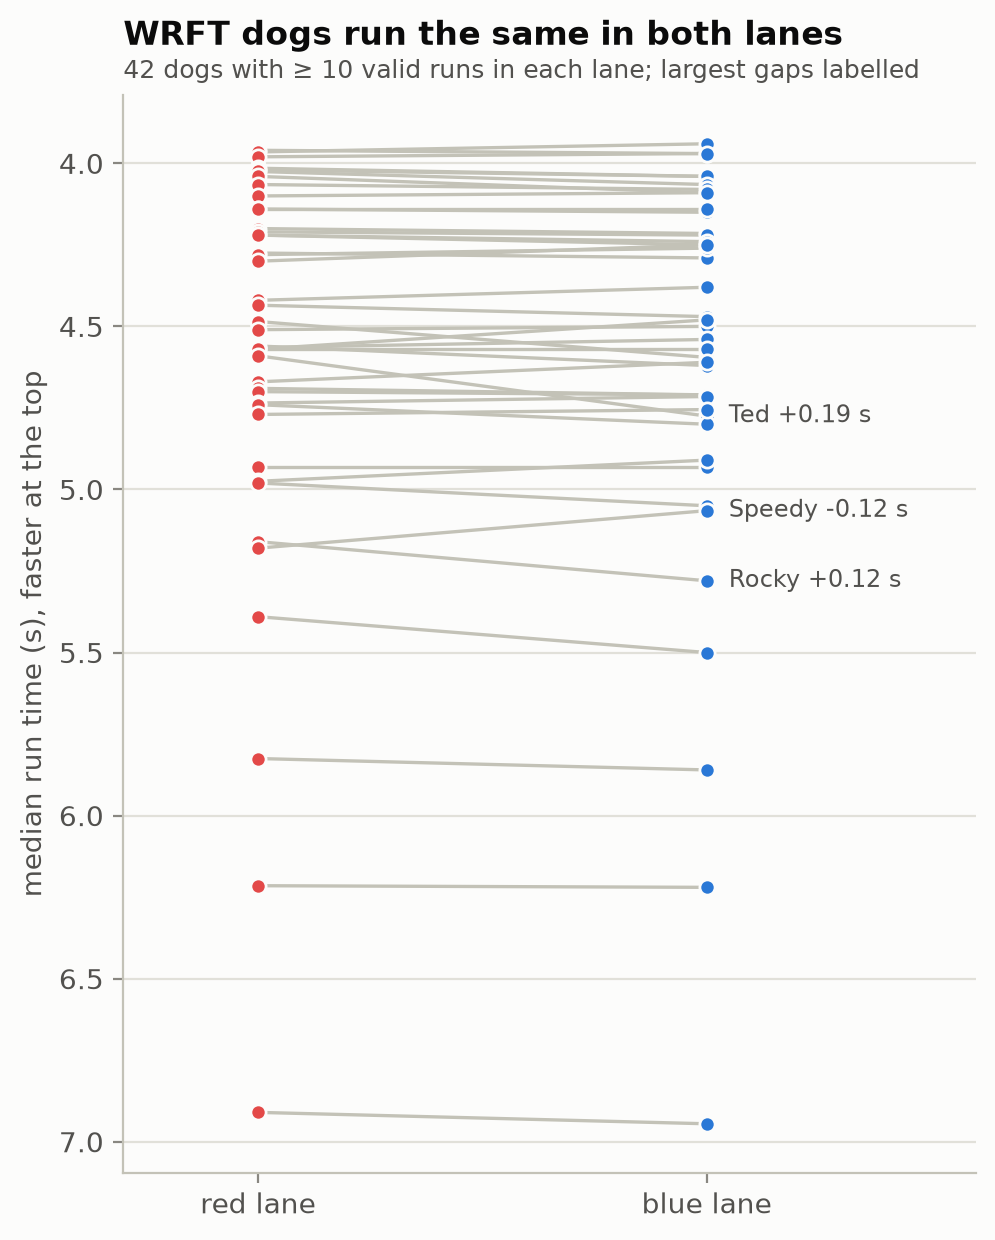

In [6]:
dog_lanes = lane.wrft_dog_lane_medians(runs)
display(Image(style.save(plots.lane_dog_slopes(dog_lanes), "lane_wrft_dogs", "phase4")))

**Q1 answer for the coach:** **No.** The lane colour has no effect that matters. Across the whole field blue is 0.006 s per run slower, which is measurable only because of the huge sample, and even the most lopsided ring-day stays below 0.035 s per run. **No lane strategy is needed**, and lane can be ignored when comparing results.

---
## Q2 – Passing onto intact/neutered male/female

### 2.1 The data

The unit is one WRFT pass: the **outgoing** dog (positions 2–4) crosses the line as the **incoming** dog returns. We ask whether the incoming dog's category changes the outgoing dog's pass or run.

In [7]:
frame = partner.pass_frame(runs)
display(partner.partner_table(frame))

,incoming_category,passes,incoming_dogs,outgoing_dogs,incoming_age_median_y,median_pass_s,held_pass_rate,ok_share,early_passes,early_pass_rate,outgoing_median_run_s,early_ci_low,early_ci_high
0,neutered male,1167,19,39,5.658,0.22,0.060,0.248,107,0.092,4.48,0.076,0.110
1,neutered female,1365,17,38,4.825,0.17,0.030,0.312,134,0.098,4.20,0.083,0.115
2,intact male,515,8,26,1.908,0.26,0.080,0.192,30,0.058,4.52,0.041,0.082
3,intact female,213,2,11,2.300,0.12,0.022,0.432,25,0.117,4.12,0.081,0.168


Two warnings before any model:

- **Intact females are only 2 dogs** (Bonnie and Moon), and intact males 8. A "category" effect for intact females is really an effect of these two dogs; no data can separate them.
- **Intact dogs are young.** Incoming intact dogs have a median age of 1.9–2.3 years, neutered ones 4.8–5.7 years. A category difference may be an **age and experience** difference. So every model is fitted twice: by category only, and **adjusted for both dogs' ages and the team**.

**A third finding shaped the outcomes.** About 5 % of timed passes are slower than 1 s. These passes were held back on purpose, and they dominate the mean pass time. So the pass is measured as two outcomes: **pass time of racing passes (≤ 1 s)** and the **held-pass rate (> 1 s)**.

### 2.2 Models

Both dogs get a random effect (crossed). A trait carried by 2 dogs then gets a CI that reflects 2 dogs, not 213 passes. Every contrast is against passing onto a **neutered male**, the largest group.

,spec,outcome,passes,chi2,df,p_value,p_holm
0,category,"pass time (racing passes, <= 1 s)",2763,2.836,3,0.418,1.000
1,category,held-pass rate (> 1 s),2902,8.213,3,0.042,0.209
2,category,tight-pass (ok) share,3260,5.380,3,0.146,0.584
3,category,early-pass rate,3260,1.792,3,0.617,1.000
4,category,run time of the outgoing dog,3187,0.236,3,0.972,1.000
5,"category, adjusted for age and team","pass time (racing passes, <= 1 s)",2763,1.857,3,0.603,1.000
6,"category, adjusted for age and team",held-pass rate (> 1 s),2902,7.993,3,0.046,0.231
7,"category, adjusted for age and team",tight-pass (ok) share,3260,5.630,3,0.131,0.524
8,"category, adjusted for age and team",early-pass rate,3260,1.073,3,0.784,1.000
9,"category, adjusted for age and team",run time of the outgoing dog,3187,1.096,3,0.778,1.000


,spec,outcome,level,incoming_dogs,estimate,ci_low,ci_high,p_holm,verdict
0,category,"pass time (racing passes, <= 1 s)",neutered female,17,-3.756e-03,-0.043,0.035,0.851,inconclusive
1,category,"pass time (racing passes, <= 1 s)",intact male,8,2.423e-02,-0.028,0.077,0.734,inconclusive
2,category,"pass time (racing passes, <= 1 s)",intact female,2,-5.102e-02,-0.130,0.028,0.619,inconclusive
3,category,held-pass rate (> 1 s),neutered female,17,2.104e-02,-0.034,0.076,0.907,inconclusive
4,category,held-pass rate (> 1 s),intact male,8,1.059e-01,0.031,0.181,0.017,meaningful difference
5,category,held-pass rate (> 1 s),intact female,2,-1.734e-02,-0.132,0.097,0.907,inconclusive
6,category,tight-pass (ok) share,neutered female,17,2.572e-02,-0.027,0.078,0.670,inconclusive
7,category,tight-pass (ok) share,intact male,8,-3.419e-02,-0.104,0.035,0.670,inconclusive
8,category,tight-pass (ok) share,intact female,2,9.162e-02,-0.008,0.192,0.219,inconclusive
9,category,early-pass rate,neutered female,17,-3.567e-03,-0.042,0.034,1.000,inconclusive


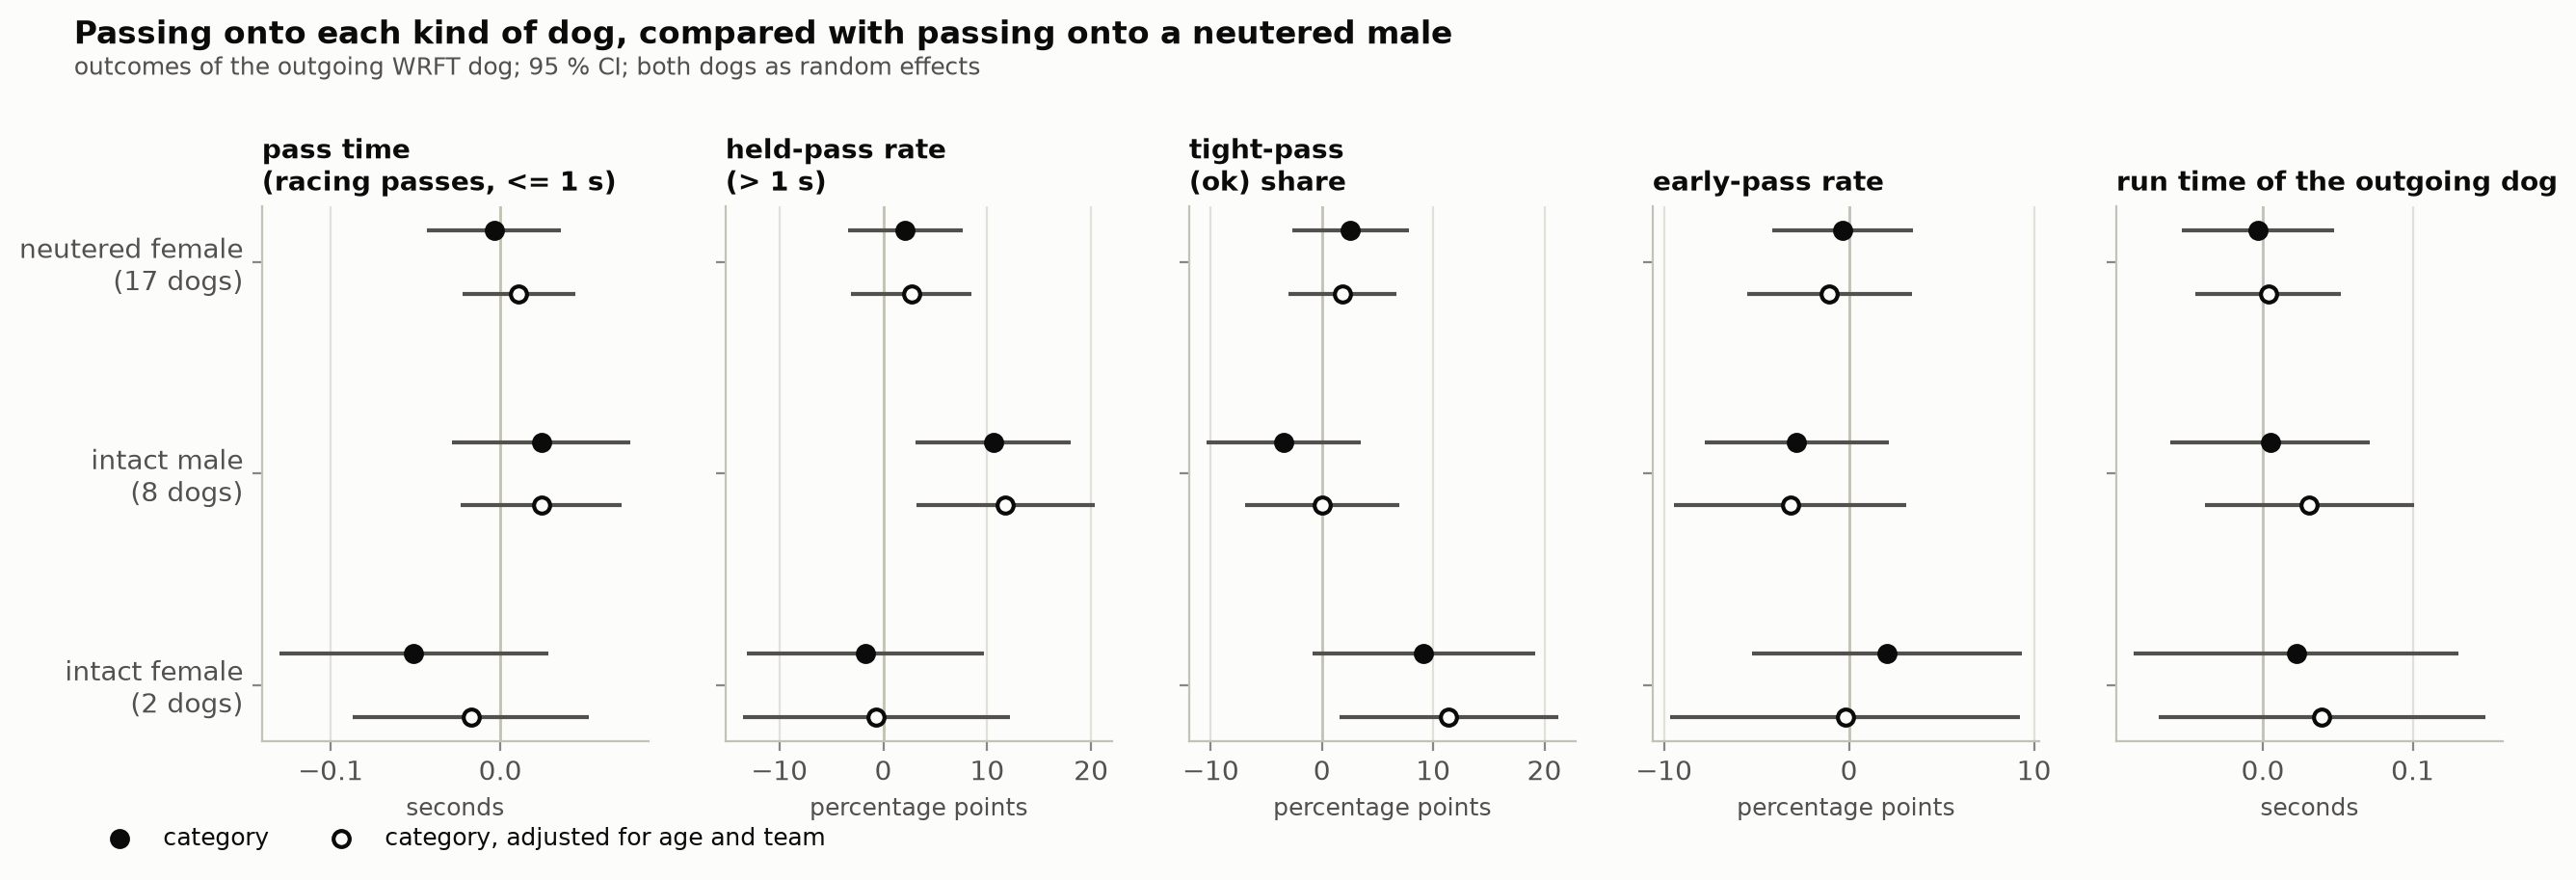

In [8]:
models = partner.partner_models(frame)
display(models["joint"])
display(models["contrasts"][["spec", "outcome", "level", "incoming_dogs", "estimate", "ci_low", "ci_high", "p_holm", "verdict"]])
display(Image(style.save(plots.partner_forest(models["contrasts"]), "partner_forest", "phase4")))

- **The incoming dog's category does not change the outgoing dog's racing pass time, `ok` share, early-pass rate or run time.** No joint test is significant after Holm, with or without the age adjustment.
- **One signal: held passes onto intact males.** When an intact male returns, the outgoing dog's pass is held back (> 1 s) about **11 percentage points more often** (CI 3–18 pp; 12 pp after the age adjustment). The "does category matter at all" test for held passes is p = 0.04, which is no longer significant after Holm over the 5 outcomes (p = 0.21). Read it as a **lead to check with the handlers, not a proven effect**: the decision to hold a pass belongs to the handler, perhaps because young intact males return less predictably.
- **Many verdicts are "inconclusive".** The data can't prove there is *no* effect within ±0.02 s, because there are only 2–8 dogs in the intact groups. The run time of the outgoing dog is the one outcome proven equivalent (neutered female vs neutered male).

### 2.3 Does the pairing matter (male onto male, neutered onto neutered)?

In [9]:
inter = partner.partner_interactions(frame)
display(inter[["interaction", "outcome", "term", "estimate", "ci_low", "ci_high", "p_value", "p_holm"]])

,interaction,outcome,term,estimate,ci_low,ci_high,p_value,p_holm
0,sex x sex,"pass time (racing passes, <= 1 s)",C(incoming_sex)[T.male]:C(own_sex)[T.male],-1.081e-02,-0.049,0.027,5.790e-01,1.000
1,sex x sex,held-pass rate (> 1 s),C(incoming_sex)[T.male]:C(own_sex)[T.male],1.337e-02,-0.028,0.054,5.222e-01,1.000
2,sex x sex,tight-pass (ok) share,C(incoming_sex)[T.male]:C(own_sex)[T.male],-3.041e-03,-0.080,0.074,9.381e-01,1.000
3,sex x sex,early-pass rate,C(incoming_sex)[T.male]:C(own_sex)[T.male],4.139e-02,-0.007,0.089,9.147e-02,0.457
4,sex x sex,run time of the outgoing dog,C(incoming_sex)[T.male]:C(own_sex)[T.male],2.694e-02,-0.005,0.059,9.844e-02,0.457
5,neutered x neutered,"pass time (racing passes, <= 1 s)",C(incoming_status)[T.neutered]:C(own_stat...,1.050e-01,0.045,0.165,5.955e-04,0.003
6,neutered x neutered,held-pass rate (> 1 s),C(incoming_status)[T.neutered]:C(own_stat...,1.689e-02,-0.047,0.081,6.041e-01,1.000
7,neutered x neutered,tight-pass (ok) share,C(incoming_status)[T.neutered]:C(own_stat...,1.584e-02,-0.105,0.137,7.971e-01,1.000
8,neutered x neutered,early-pass rate,C(incoming_status)[T.neutered]:C(own_stat...,-9.609e-03,-0.088,0.069,8.098e-01,1.000
9,neutered x neutered,run time of the outgoing dog,C(incoming_status)[T.neutered]:C(own_stat...,-4.957e-03,-0.053,0.043,8.386e-01,1.000


- **Sex × sex:** no pairing effect on any outcome.
- **Neutered × neutered:** the interaction term on racing pass time is significant (+0.105 s, Holm p = 0.003). It is hard to read on its own, so the same 2 × 2 is also fitted as four cells. Only one cell stands out: **intact onto intact** (+0.05 s; CI −0.04 to +0.15) – **64 passes between young dogs**, not significant as a cell. This points to inexperience, not to sex or neuter status.

### 2.4 Sensitivity

In [10]:
sens = partner.partner_sensitivity(runs, frame)
display(sens[["variant", "outcome", "level", "estimate", "ci_low", "ci_high", "p_value", "joint_p", "passes"]])

,variant,outcome,level,estimate,ci_low,ci_high,p_value,joint_p,passes
0,merged: sex only,"pass time (racing passes, <= 1 s)",male,0.016,-0.019,0.051,0.362,0.362,2763
1,merged: sex only,held-pass rate (> 1 s),male,0.012,-0.040,0.063,0.663,0.663,2902
2,merged: sex only,tight-pass (ok) share,male,-0.044,-0.090,0.003,0.066,0.066,3260
3,merged: sex only,early-pass rate,male,-0.010,-0.041,0.022,0.547,0.547,3260
4,merged: sex only,run time of the outgoing dog,male,0.002,-0.043,0.047,0.937,0.937,3187
5,merged: neutered only,"pass time (racing passes, <= 1 s)",neutered,-0.005,-0.047,0.038,0.830,0.830,2763
6,merged: neutered only,held-pass rate (> 1 s),neutered,-0.065,-0.126,-0.003,0.039,0.039,2902
7,merged: neutered only,tight-pass (ok) share,neutered,0.008,-0.046,0.062,0.773,0.773,3260
8,merged: neutered only,early-pass rate,neutered,0.013,-0.024,0.049,0.503,0.503,3260
9,merged: neutered only,run time of the outgoing dog,neutered,-0.010,-0.064,0.043,0.702,0.702,3187


The conclusions hold when the categories are merged (sex only, neutered only), when the intact females or the dogs under 18 months are left out, when `ok` is counted as 0 s or 0.08 s, and in a logistic GEE. **The only result that moves is mean pass time with held passes included:** "intact male +0.26 s" appears there, and it is the held-pass effect again.

The held-pass signal itself is stable. It is +11 pp with the intact females left out, and **+14 pp (CI 5–23) with the dogs under 18 months left out**. In the merged "neutered only" version, passes onto neutered dogs are held 6.5 pp less often. So the signal is not just Hank and Bonnie being very young.

**Q2 answer for the coach:** **No measurable effect on racing performance.** Passing onto an intact or neutered male or female does not change how fast or how cleanly the next dog passes or runs. The one pattern worth a conversation: **passes onto young intact males are held back more often.** If those holds are not deliberate, they cost time. The data are thin (8 intact males, 2 intact females), so this is "no evidence of an effect", not proof of none.

---
## Q3 – Per competition

### 3.1 Dog-adjusted speed index

Raw times mix up *who* ran and *where*. The **speed index** compares the same dogs with themselves: how much faster (−) or slower (+) they ran on that day than on an average day of the season. It bundles venue, ground and weather; Phase 4B separates them.

In [11]:
index = {s: competition.speed_index(r, s) for s, (_, r) in samples.items()}
display(index["field"][["competition", "ring", "date", "runs", "dogs", "pct", "ci_low", "ci_high", "seconds_at_median"]])

,competition,ring,date,runs,dogs,pct,ci_low,ci_high,seconds_at_median
0,Hanácké škvarek,<NA>,2023-04-22,410,43,0.468,0.143,0.793,1.997e-02
1,Hanácké škvarek,<NA>,2023-04-23,481,40,0.949,0.642,1.258,4.053e-02
2,Eager´s Cup,1,2023-05-06,1171,134,-0.087,-0.295,0.122,-3.712e-03
3,Eager´s Cup,1,2023-05-07,1288,129,-0.006,-0.211,0.200,-2.422e-04
4,Eager´s Cup,2,2023-05-06,1254,152,-0.057,-0.270,0.158,-2.415e-03
5,Eager´s Cup,2,2023-05-07,1454,141,-0.176,-0.381,0.029,-7.534e-03
6,Flyvaryors turnaj,<NA>,2023-05-20,1350,159,-0.450,-0.632,-0.267,-1.919e-02
7,Flyvaryors turnaj,<NA>,2023-05-21,1496,148,-0.121,-0.295,0.053,-5.170e-03
8,MED's Trophy,<NA>,2023-06-10,1070,123,-0.149,-0.355,0.058,-6.349e-03
9,MED's Trophy,<NA>,2023-06-11,1142,115,-0.127,-0.324,0.070,-5.429e-03


### 3.2 WRFT, competition day by competition day

One row per day: results and fault profile (Phase 3 metrics), why heats were lost, the gap to the other teams of the same divisions, the speed index, the lane effect and the weather. The full table is `reports/phase4a/competition_days.csv`.

,competition,date,teams,heats,win_rate,clean_heat_rate,median_clean_time,share_losses_avoidable,peer_gap_win_rate,peer_gap_win_rate_p_holm,speed_index_wrft_pct,speed_index_field_pct,temp_mean_c,precip_total_mm
0,Hanácké škvarek,2023-04-22,6,73,0.370,0.370,17.710,0.304,-2.348e-01,2.571e-01,0.813,0.468,17.611,0.0
1,Hanácké škvarek,2023-04-23,6,88,0.500,0.534,17.560,0.364,-1.058e-16,1.000e+00,1.280,0.949,15.067,0.0
2,Eager´s Cup,2023-05-06,6,73,0.315,0.452,17.650,0.100,-3.862e-02,1.000e+00,0.281,-0.071,14.182,3.0
3,Eager´s Cup,2023-05-07,6,64,0.344,0.484,17.270,0.286,-1.871e-01,2.387e-02,0.587,-0.096,8.808,0.0
4,Flyvaryors turnaj,2023-05-20,3,35,0.186,0.286,16.840,0.179,-2.080e-01,7.601e-04,-0.824,-0.450,19.300,1.9
5,Flyvaryors turnaj,2023-05-21,3,42,0.488,0.643,16.670,0.238,-1.460e-02,1.000e+00,-0.923,-0.121,20.680,0.1
6,BCCCZ mistrovství,2023-06-24,7,84,0.464,0.405,17.535,0.333,-6.944e-02,1.000e+00,0.168,0.581,19.162,0.0
7,BCCCZ mistrovství,2023-06-25,7,99,0.485,0.616,18.045,0.314,-2.975e-02,1.000e+00,1.258,1.272,22.750,0.0
8,Crazy Cup,2023-07-01,6,72,0.250,0.528,17.110,0.056,-1.113e-01,6.006e-01,-0.087,-0.279,19.745,0.3
9,Crazy Cup,2023-07-02,6,77,0.610,0.766,17.160,0.267,1.397e-01,1.000e+00,0.098,0.069,18.317,3.1


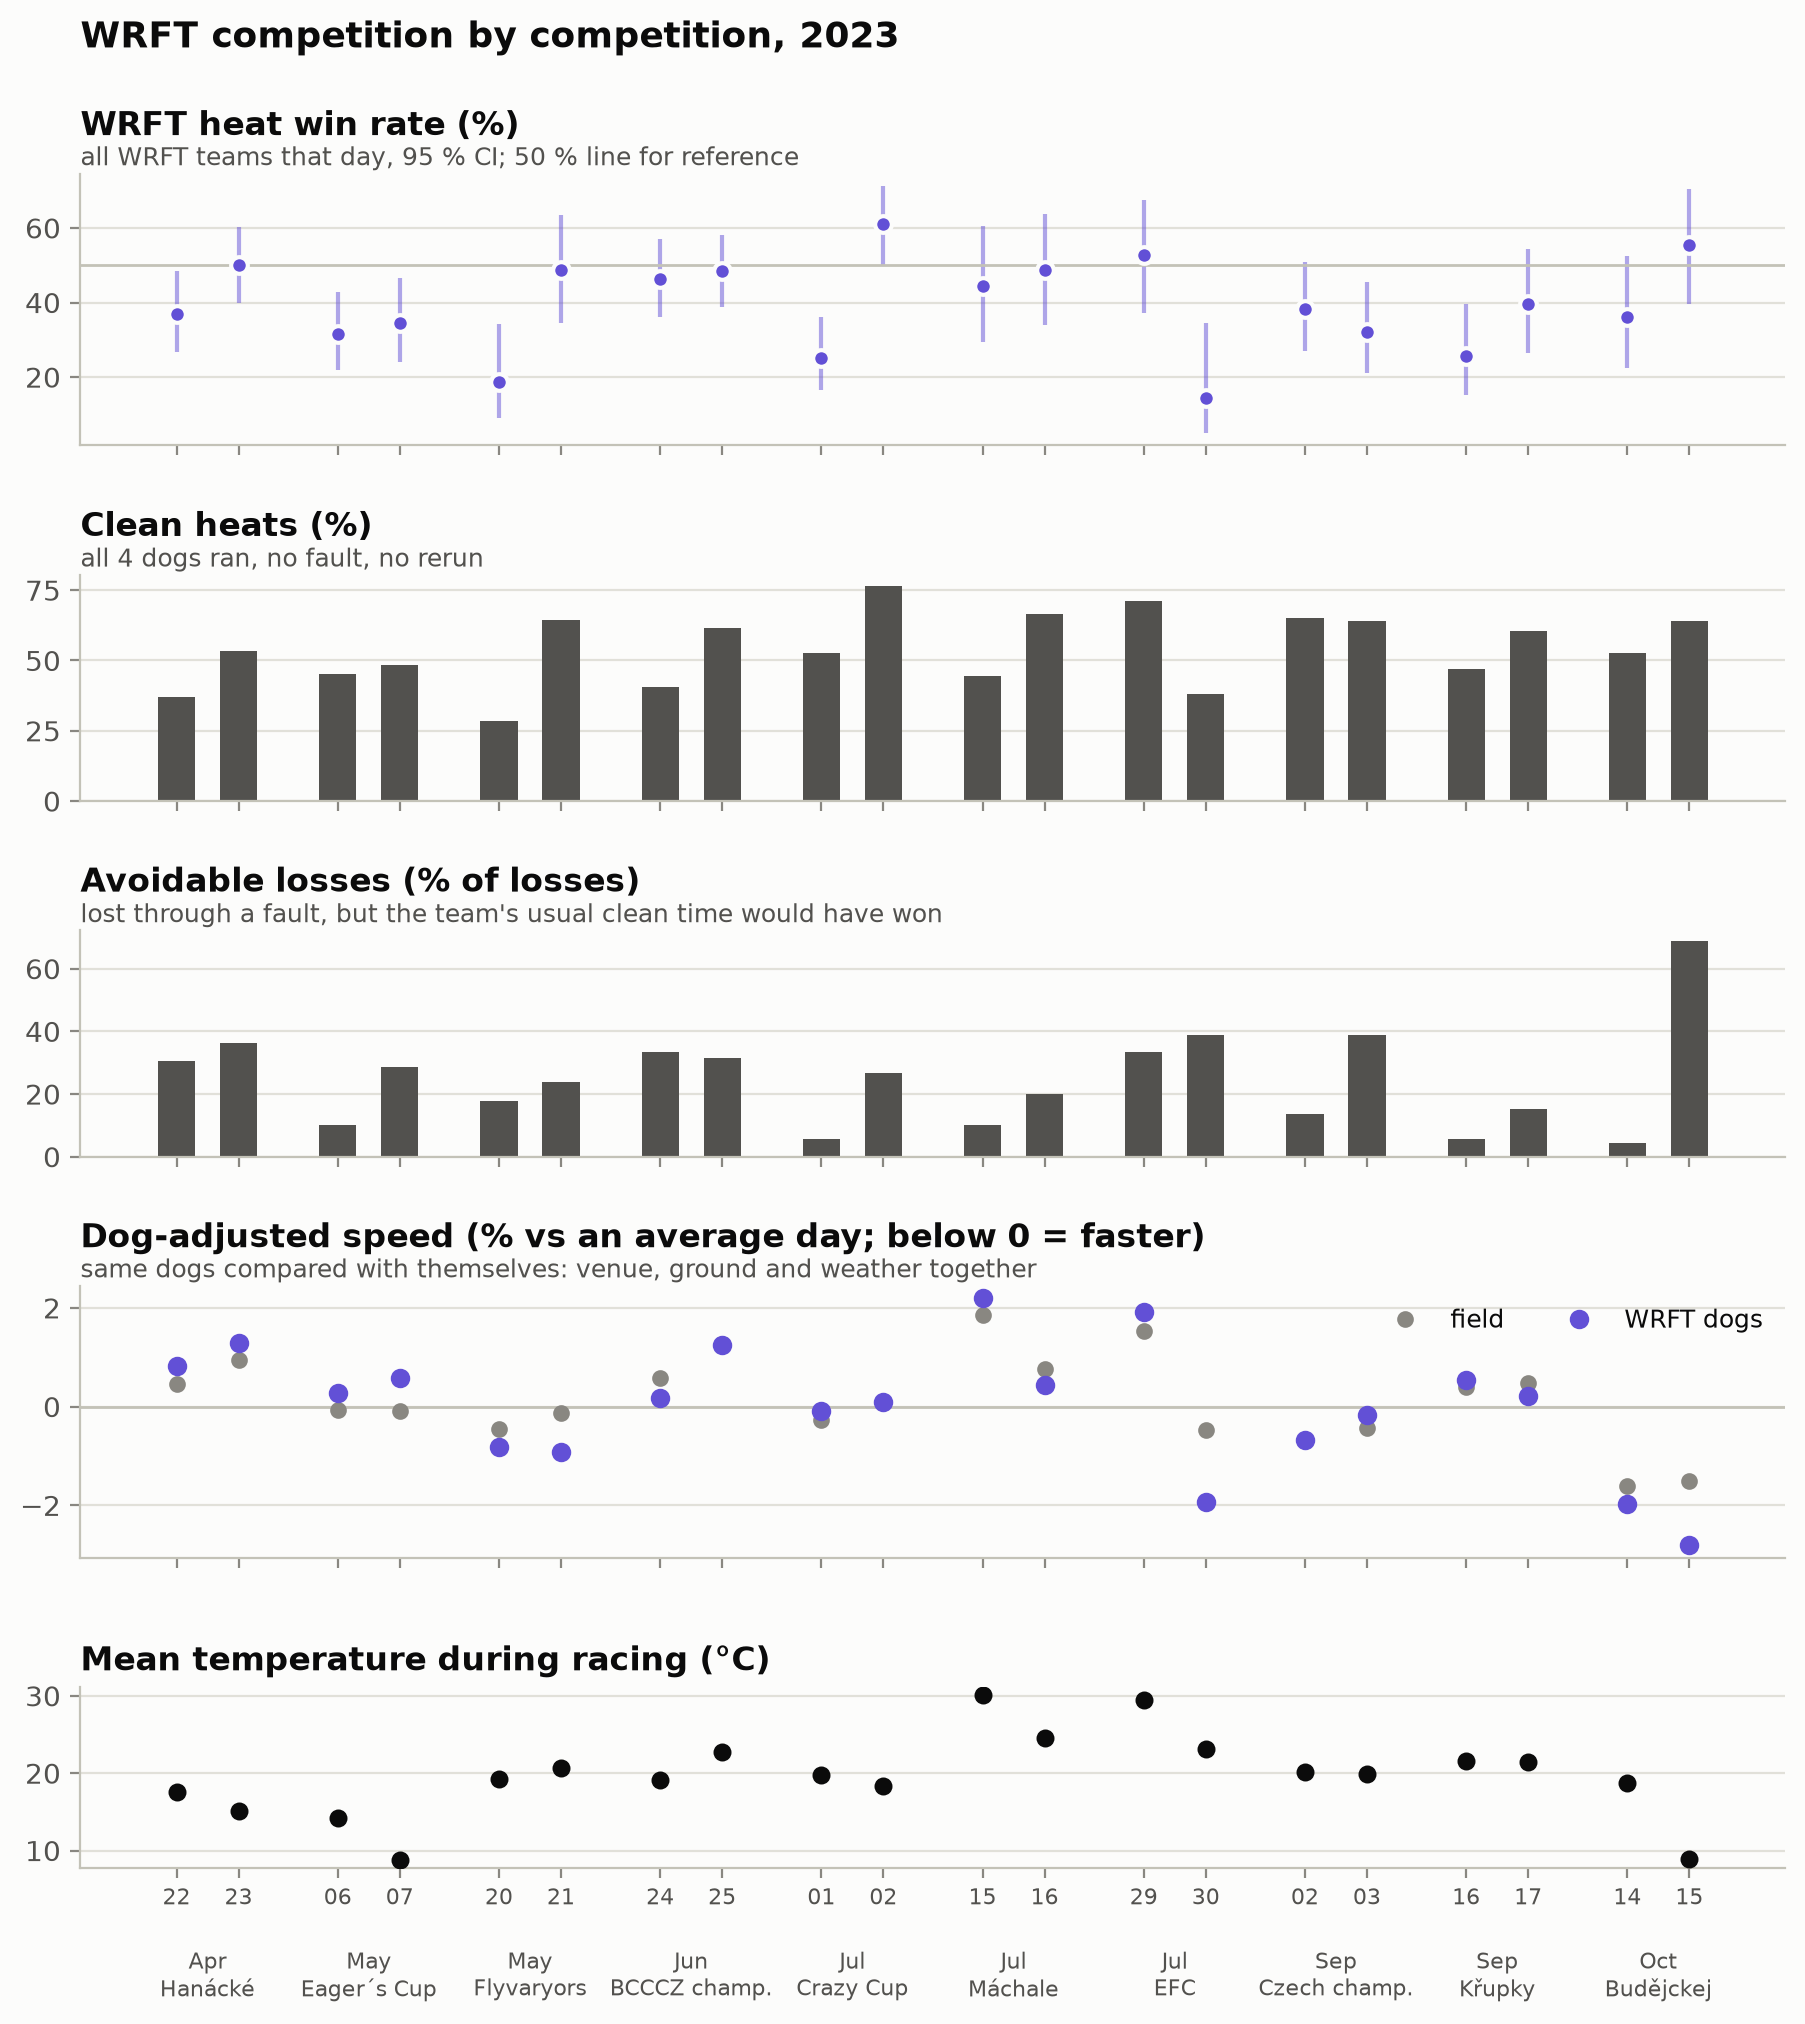

In [12]:
weather_day = pd.read_csv(config.PROCESSED / "weather_day.csv")
days = competition.competition_days(heats, runs, weather_day, lane_days, index["WRFT"], index["field"])
display(days[["competition", "date", "teams", "heats", "win_rate", "clean_heat_rate", "median_clean_time",
              "share_losses_avoidable", "peer_gap_win_rate", "peer_gap_win_rate_p_holm",
              "speed_index_wrft_pct", "speed_index_field_pct", "temp_mean_c", "precip_total_mm"]])
display(Image(style.save(plots.competition_small_multiples(days), "competition_days", "phase4")))

What stands out:

- **The hottest days were the slowest.** Máchale Saturday (30 °C) and EFC Saturday (29 °C) are the slowest days of the season for the same dogs (+1.5 to +2.2 %, about +0.08 s per run). The two October days at Budějckej are the fastest (−1.5 to −2.8 %). Its Sunday was the coldest day of the season (9 °C), but its Saturday was a mild 19 °C, and the other 9 °C day (Eager's Cup Sunday) was not fast. So venue and ground matter as well as temperature. This is the coach's weather hypothesis showing up; Phase 4B tests it properly, separating weather from venue and season.
- **Win rate swings more with faults than with speed.** The best days (Crazy Cup Sunday 61 %, Budějckej Sunday 56 %) have high clean-heat rates. EFC Sunday (14 % wins) and Flyvaryors Saturday (19 %) have the lowest.
- **Budějckej Sunday:** 69 % of the losses were avoidable. The dogs were at their fastest of the season, and faults threw the heats away.
- WRFT's win rate was below its division peers on 4 days after Holm (Eager's Cup Sunday, Flyvaryors Saturday, EFC Sunday, Czech championship Sunday). It was above them on none. Clean times never differed from the peers after Holm, which again points at faults rather than speed.

### 3.3 Each team at each competition

In [13]:
teams = competition.competition_teams(heats, runs)
display(teams[["competition", "team", "division", "heats", "win_rate", "clean_heat_rate", "median_clean_time",
               "rank", "teams_in_div", "gap_to_div_median"]])

,competition,team,division,heats,win_rate,clean_heat_rate,median_clean_time,rank,teams_in_div,gap_to_div_median
0,Hanácké škvarek,WildRunners Maximini,1,23,0.304,0.391,18.590,5.0,5,1.010
1,Hanácké škvarek,WildRunners Nightfall,1,26,0.462,0.577,17.580,3.0,5,0.000
2,Hanácké škvarek,WildRunners XXL,2,20,0.250,0.350,22.540,4.0,4,3.392
3,Hanácké škvarek,WildRunners Zephyr,2,31,0.484,0.290,18.885,2.0,4,-0.263
4,Hanácké škvarek,WildRunners dreamers,1,29,0.517,0.690,16.790,2.0,5,-0.790
5,Hanácké škvarek,WildRunners hopefuls,1,32,0.531,0.438,16.090,1.0,5,-1.490
6,Eager´s Cup,WildRunners Maximini,5,20,0.350,0.350,17.950,5.0,6,0.330
7,Eager´s Cup,WildRunners Nightfall,4,27,0.519,0.444,17.070,1.0,5,-0.130
8,Eager´s Cup,WildRunners XXL,8,24,0.167,0.417,21.260,7.0,7,1.960
9,Eager´s Cup,WildRunners Zephyr,8,22,0.364,0.591,19.890,6.0,7,0.590


### 3.4 Each dog at each competition

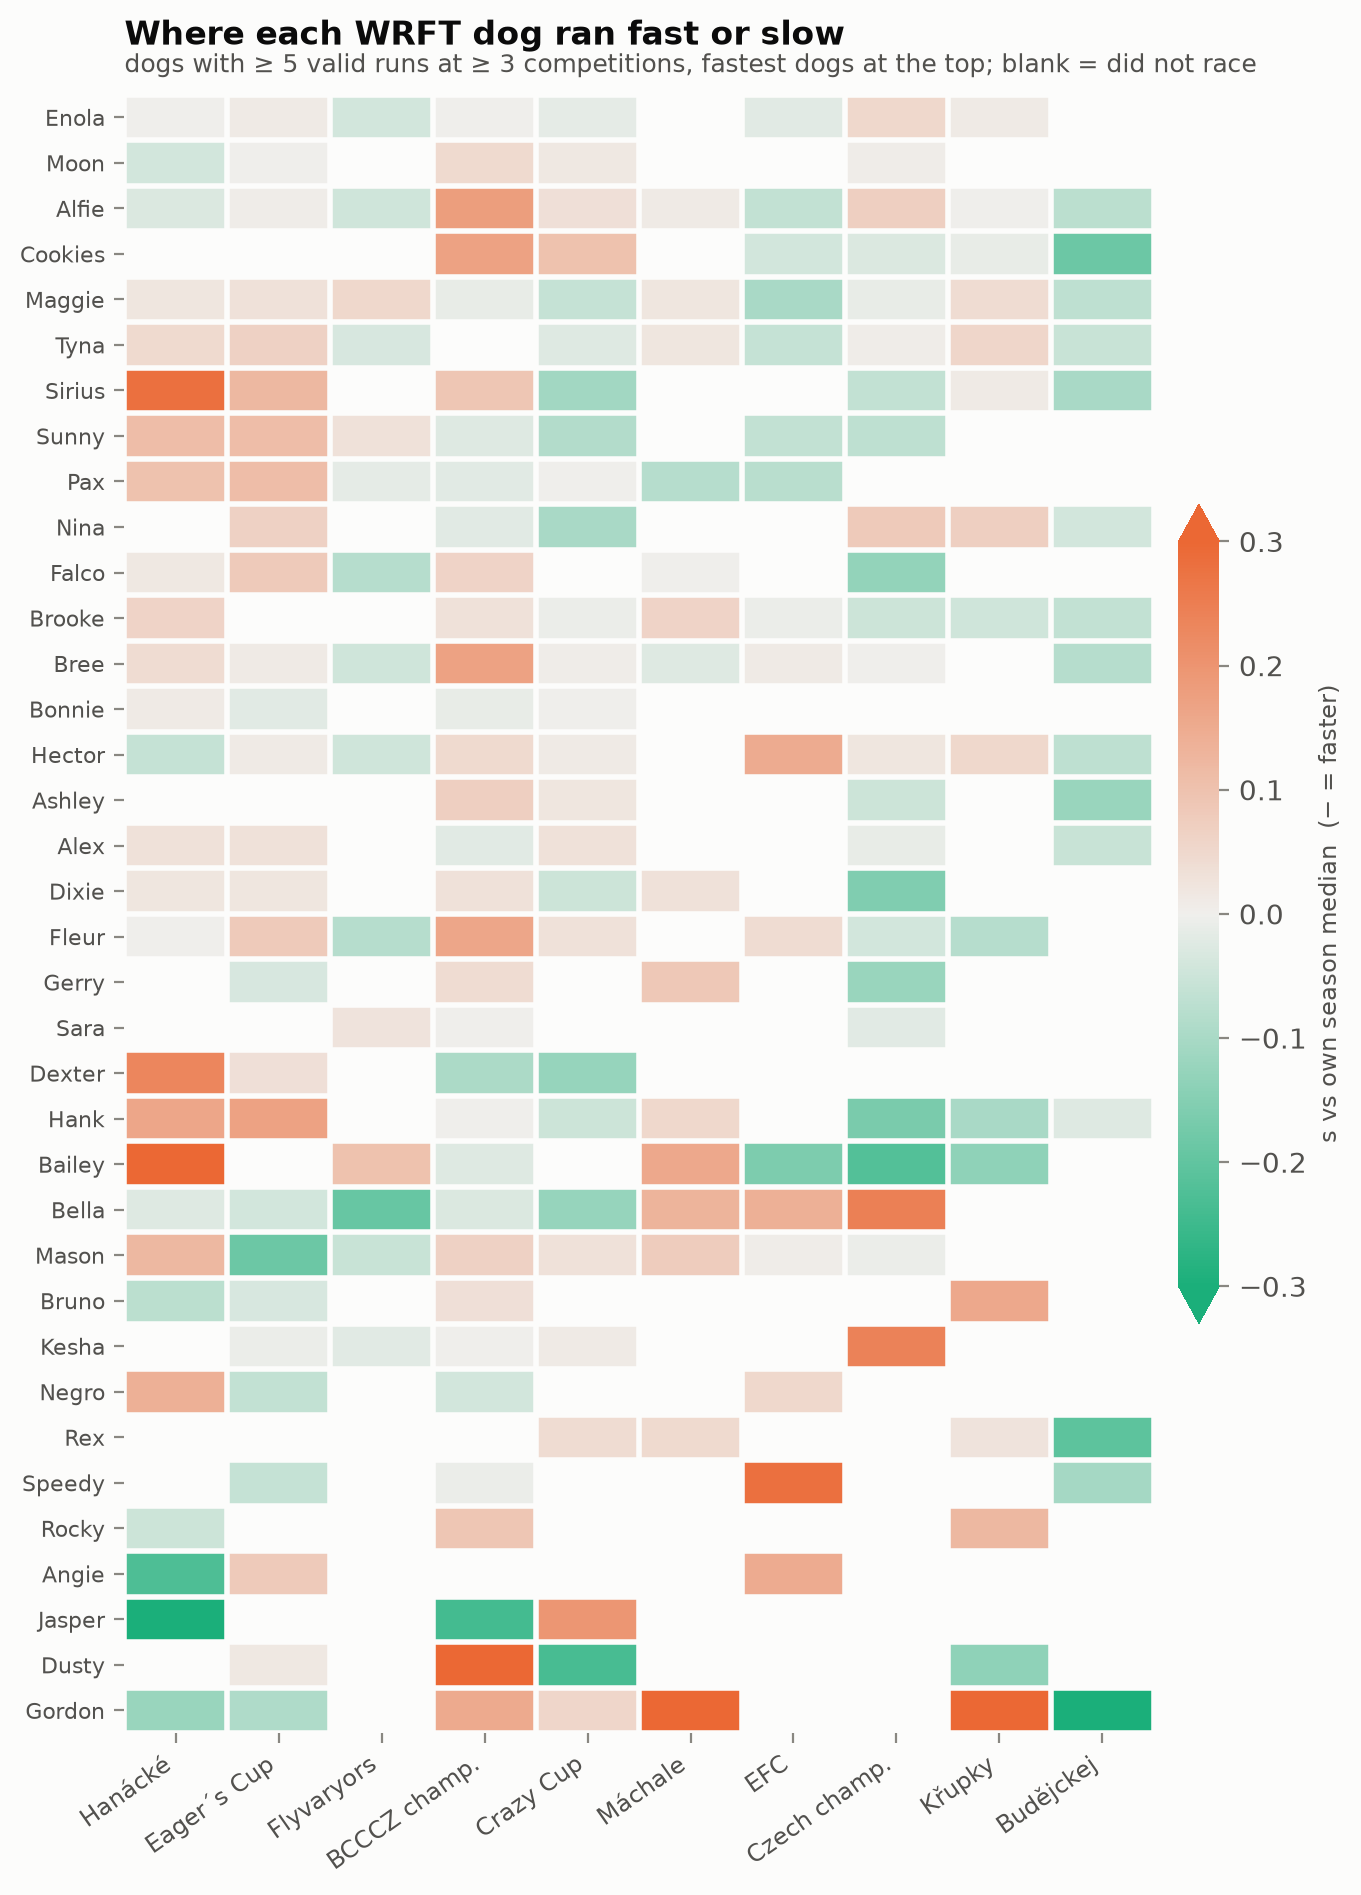

In [14]:
dog_comp = competition.dog_by_competition(runs)
display(Image(style.save(plots.dog_competition_heatmap(dog_comp), "dog_by_competition", "phase4")))

Each cell is a dog's median run at that competition minus its own season median. Hurdle height and running position can differ between competitions, so this is descriptive. Most dogs run within ±0.1 s of their median everywhere, so a single slow competition is rarely a pattern. The clearest cluster is the **season opener** (Hanácké, April): Sirius, Bailey and Dexter were 0.2–0.3 s slower than their season median there, which fits the season trend below. Gordon, the 15 cm height dog, swings the most (slow at Máchale and Křupky, fast at Budějckej); his hurdle height changes with the team, so this is a case for the line-up work in 4B.

### 3.5 Season trend

In [15]:
display(pd.concat([competition.season_trend(r, s) for s, (_, r) in samples.items()], ignore_index=True))

,sample,runs,dogs,pct_per_30_days,ci_low,ci_high,seconds_per_30_days,p_value
0,field,32777,903,-0.186,-0.211,-0.161,-0.008,1.620e-49
1,WRFT,4340,50,-0.291,-0.360,-0.222,-0.012,2.000e-16


The same dogs got faster through the season: WRFT dogs by **0.29 % per month** (about 0.013 s per run per month, roughly 0.07 s per run from April to October), the field by 0.19 %. **Caution:** the coldest days are at both ends of the season (Eager's Cup in May and Budějckej in October, both 9 °C), and the fastest days of the season are at Budějckej in October. Part of this "trend" may be temperature. Phase 4B fits trend and weather together.

---
## Summary

| Question | Answer | Confidence |
|---|---|---|
| **Q1** Lane colour | **No effect that matters.** Field: blue +0.006 s per run (real but negligible); the largest venue asymmetry is 0.032 s per run; every start, pass and fault rate is equivalent. | High for speed; win and fault rates of WRFT alone are inconclusive (too few races) |
| **Q2** Passing onto intact/neutered male/female | **No measurable effect** on racing pass time, `ok` share, early passes or run time. A lead: passes onto young intact males are held back ~11 pp more often. | Moderate: 2 intact females and 8 intact males keep CIs wide |
| **Q3** Per competition | Full tables in `reports/phase4a/`. The two hottest days were the slowest and the October event the fastest; win rate follows the clean-heat rate; WRFT trailed its peers on 4 days, always through faults, never through clean time; avoidable losses peak at Budějckej Sunday (69 %). | Descriptive; the weather is tested in 4B |